In [8]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB

L_arr = [16]
J_arr = [1]
h_arr = [0.05]
lamb_arr = [0.7]
g_arr = [8]

x_basis = False

fractional_gates = True

particle_pair_left_positions = [L//2 - 1 for L in L_arr]
particle_pair_length = 1

final_time = 8
steps = 35

shots = 50000

odr = True

execution_database = "z2_chain_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

In [9]:
from qiskit_ibm_runtime import QiskitRuntimeService
from cobos.tokens import ibm_token, group_instance, group_instance2
# from fradm.tokens import ibm_token, group_instance

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"

eplg_absolute = 4.78e-3

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance)
backend_fractional = service.backend(device, use_fractional_gates=True)
backend_conventional = service.backend(device, use_fractional_gates=False)

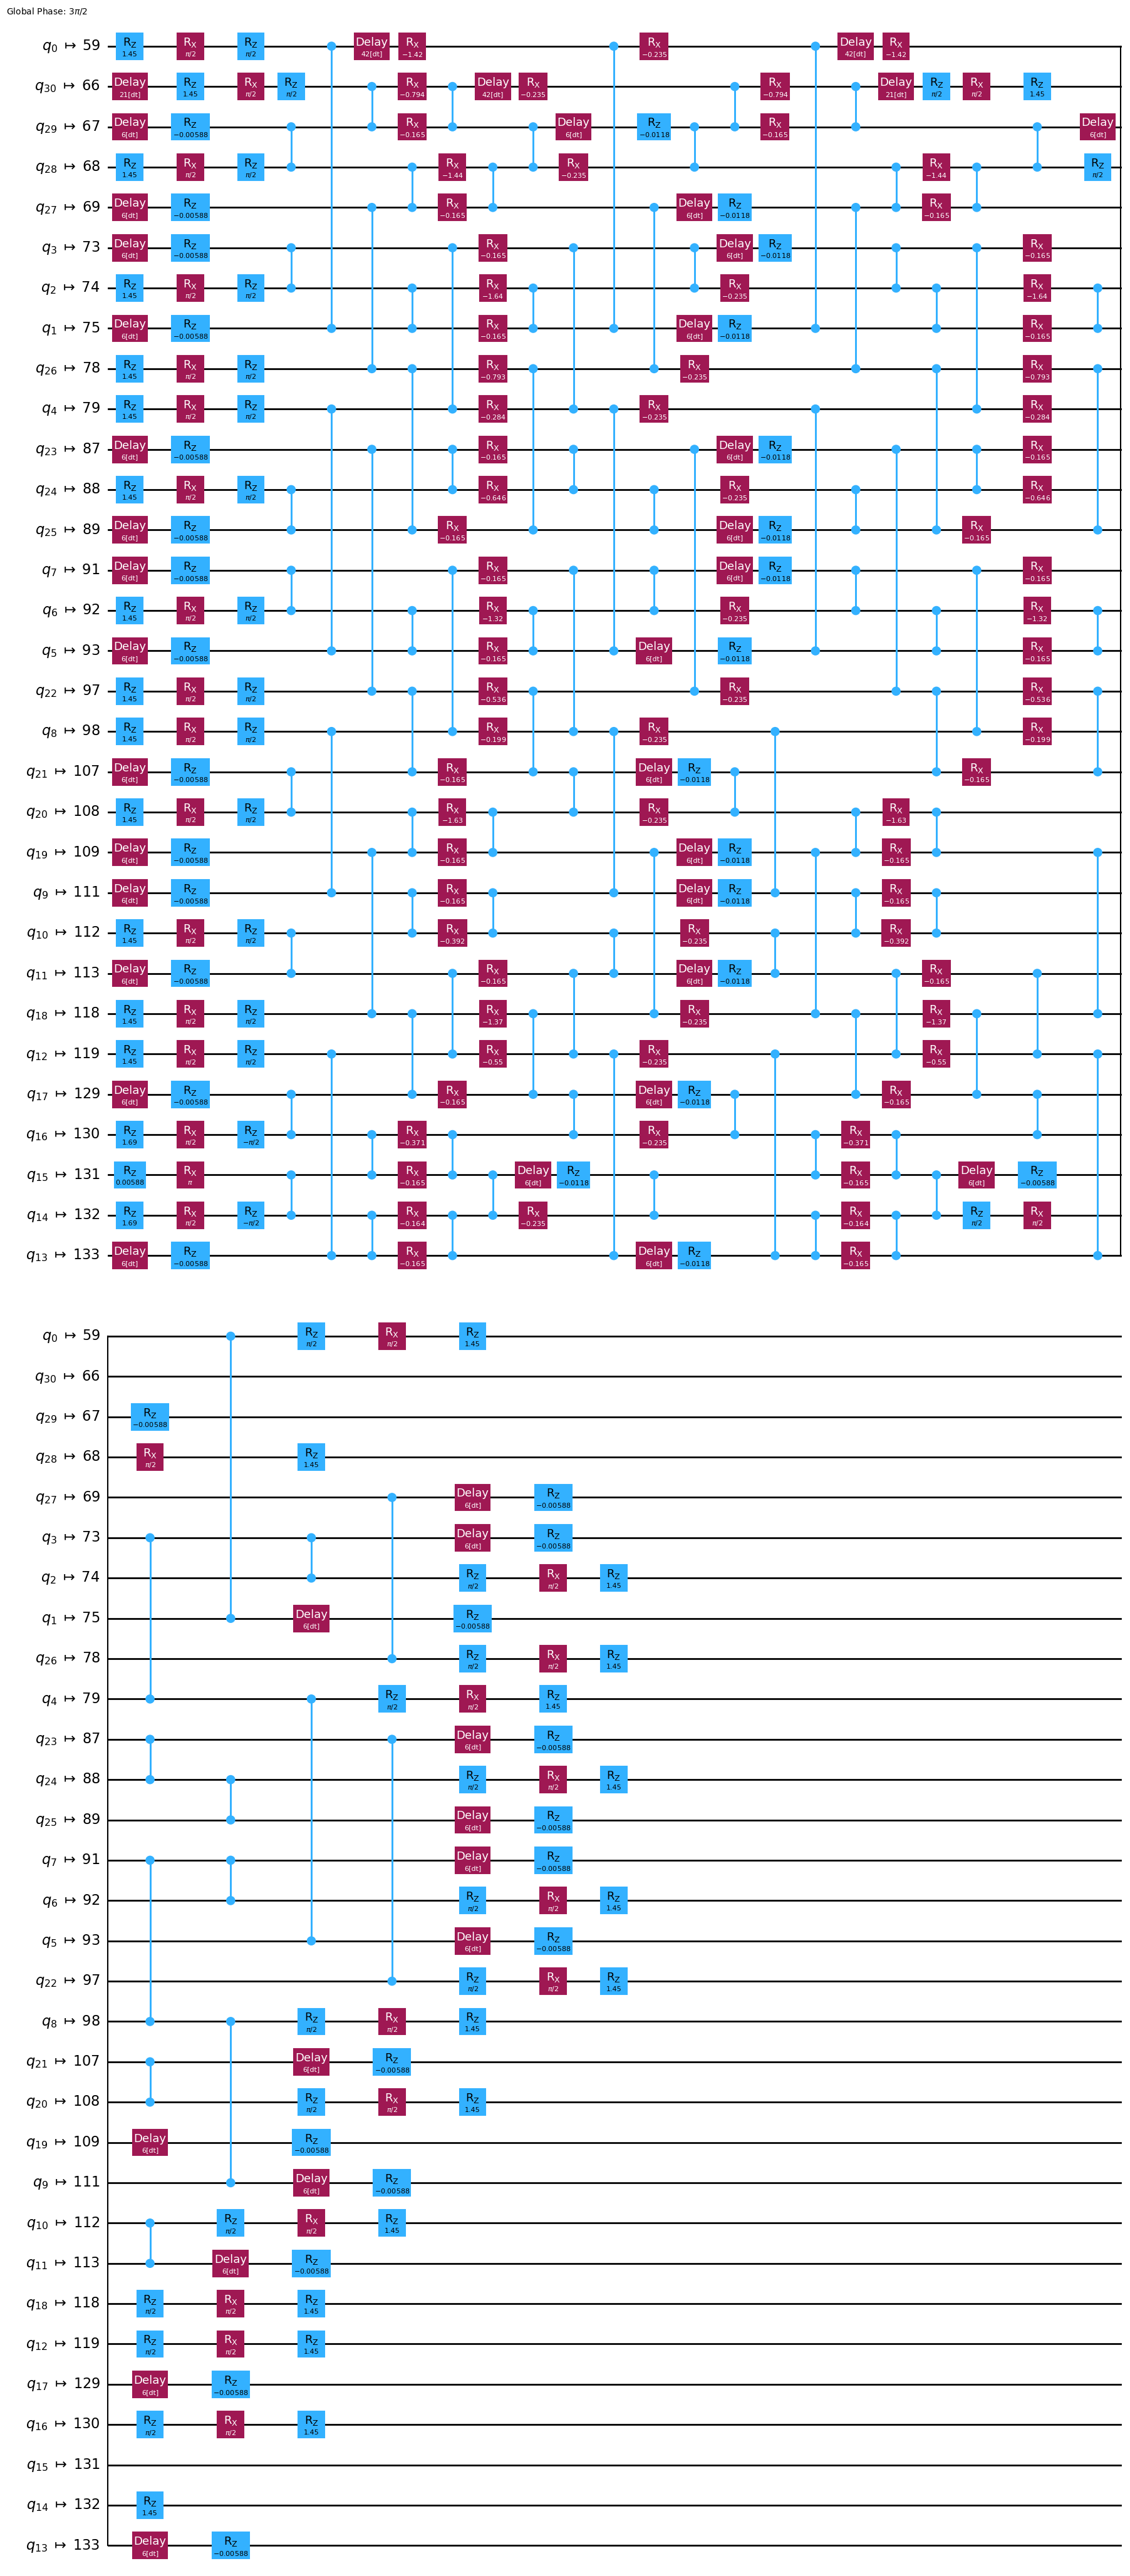

In [10]:
from z2chain.circs import physical_particle_pair_quench_simulation_circuits, erradj_particle_pair_quench_simulation_circuits, odr_compuncomp_circuits
from z2chain.operators import local_pauli_z, local_pauli_x, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.circs import generate_and_save_circs
from functools import partial
from itertools import product
import os

fractional_gates = True

optimization_level = 2

pcircuits = [] # circuits[L][params][t]
if odr: odr_circuits = [] # odr_circuits[L][params][t]
observable_generating_funcs = [] #observable_generating_funcs[L][i]
postselection_operators_funcs = []
extra_options = []

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": False,
        "enable_measure": True,
        "num_randomizations": shots//100,
        "shots_per_randomization": 100
    }
}

for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    qubits_inds = get_backend_best_qubit_chain(backend_fractional, 2*L-1)
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2chain_quench_circs_{device}_maxt_{final_time}_steps_{steps}_L_{L}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_pp_{pp_ps}_pl_{particle_pair_length}_xbasis_{x_basis}.qpy")
        circs_func_args = (L, J, h, lamb, pp_ps, particle_pair_length, final_time, steps, backend_fractional, optimization_level, eplg_absolute, g, qubits_inds, x_basis)
        physical_circuits = erradj_particle_pair_quench_simulation_circuits(L, J, h, lamb, pp_ps, particle_pair_length, final_time, steps, backend_fractional, optimization_level, eplg_absolute, g, qubits_inds, x_basis=x_basis, force_even=True)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "L": L, "J": J, "h": h, "λ":lamb, "g": g, "particle_pair_position": pp_ps, "particle_pair_length": particle_pair_length, "final_time": final_time, "eplg": eplg_absolute} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (L, J, h, lamb, final_time, steps, backend_fractional, eplg_absolute, g, pp_ps, particle_pair_length, qubits_inds, x_basis)
            this_odr_circuits.append(odr_compuncomp_circuits(*odr_func_args))
    pcircuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([partial(local_pauli_z if not x_basis else local_pauli_x, qubit_ind=i) for i in range(2*L-1)])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators((nqubits + 1)//2, x_basis))
    extra_options.append(this_extra_options)

pcircuits[0][0][1].draw(output="mpl", idle_wires=False, filename="transpiled_circ_erradj.png")

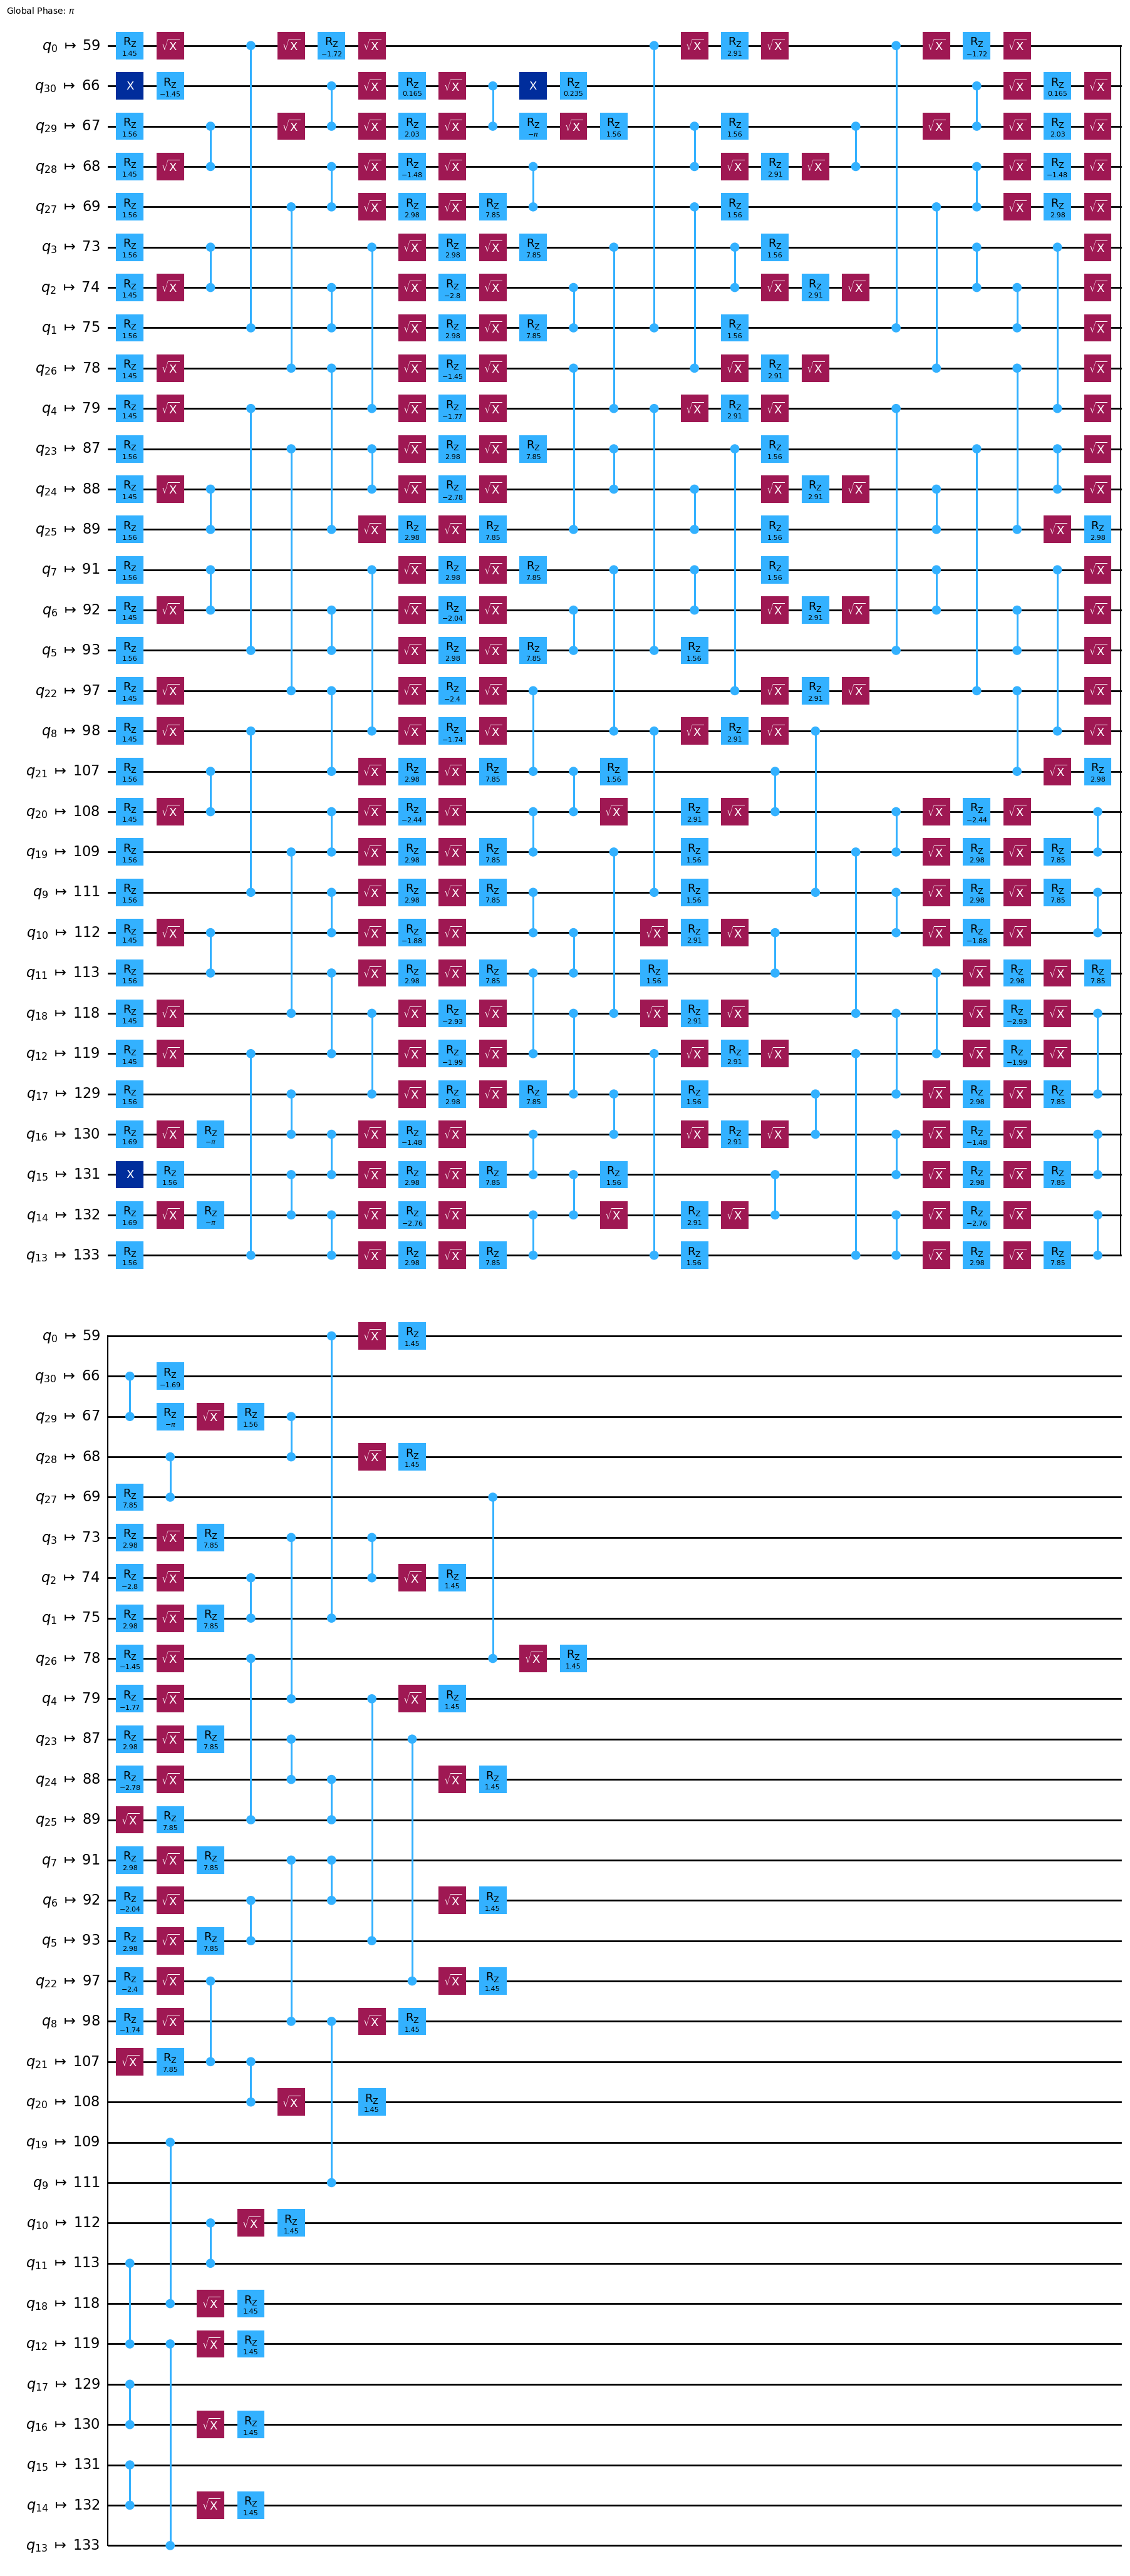

In [11]:
from z2chain.circs import physical_particle_pair_quench_simulation_circuits, erradj_particle_pair_quench_simulation_circuits, odr_compuncomp_circuits
from z2chain.operators import local_pauli_z, local_pauli_x, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.circs import generate_and_save_circs
from functools import partial
from itertools import product
import os

fractional_gates = False

optimization_level = 2

npcircuits = [] # circuits[L][params][t]
if odr: odr_circuits = [] # odr_circuits[L][params][t]
observable_generating_funcs = [] #observable_generating_funcs[L][i]
postselection_operators_funcs = []
extra_options = []

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": False,
        "enable_measure": True,
        "num_randomizations": shots//100,
        "shots_per_randomization": 100
    }
}

for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    qubits_inds = get_backend_best_qubit_chain(backend_conventional, 2*L-1)
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2chain_quench_circs_{device}_maxt_{final_time}_steps_{steps}_L_{L}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_pp_{pp_ps}_pl_{particle_pair_length}_xbasis_{x_basis}.qpy")
        circs_func_args = (L, J, h, lamb, pp_ps, particle_pair_length, final_time, steps, backend_conventional, optimization_level, eplg_absolute, g, qubits_inds, x_basis)
        physical_circuits = erradj_particle_pair_quench_simulation_circuits(L, J, h, lamb, pp_ps, particle_pair_length, final_time, steps, backend_conventional, optimization_level, eplg_absolute, g, qubits_inds, x_basis=x_basis, force_even=True)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "L": L, "J": J, "h": h, "λ":lamb, "g": g, "particle_pair_position": pp_ps, "particle_pair_length": particle_pair_length, "final_time": final_time, "eplg": eplg_absolute} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (L, J, h, lamb, final_time, steps, backend_conventional, eplg_absolute, g, pp_ps, particle_pair_length, qubits_inds, x_basis)
            this_odr_circuits.append(odr_compuncomp_circuits(*odr_func_args))
    npcircuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([partial(local_pauli_z if not x_basis else local_pauli_x, qubit_ind=i) for i in range(2*L-1)])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators((nqubits + 1)//2, x_basis))
    extra_options.append(this_extra_options)

npcircuits[0][0][1].draw(output="mpl", idle_wires=False, filename="transpiled_circ_erradj.png")

In [6]:
print(pcircuits[0][0][-1].duration)
print(npcircuits[0][0][-1].duration)

1734
None


In [16]:
from qiskit_ibm_runtime.transpiler.passes.scheduling import ALAPScheduleAnalysis, PadDelay
from qiskit.transpiler.passmanager import PassManager

this_circuits = pcircuits[0][0]

sched_pm = PassManager([ALAPScheduleAnalysis(backend_fractional.instruction_durations), PadDelay(backend_fractional.instruction_durations)])

p_s_circuits = [sched_pm.run(c) for c in this_circuits]
p_s_circs_duration = [c.duration for c in p_s_circuits]

In [17]:
from qiskit_ibm_runtime.transpiler.passes.scheduling import ALAPScheduleAnalysis, PadDelay
from qiskit.transpiler.passmanager import PassManager

this_circuits = npcircuits[0][0]

sched_pm = PassManager([ALAPScheduleAnalysis(backend_conventional.instruction_durations), PadDelay(backend_conventional.instruction_durations)])
np_s_circuits = [sched_pm.run(c) for c in this_circuits]
np_s_circs_duration = [c.duration for c in np_s_circuits]

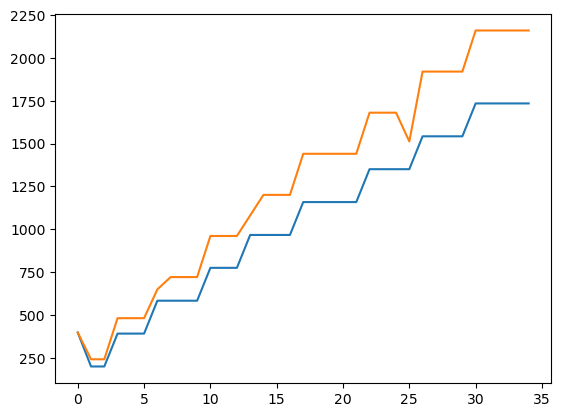

In [18]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(p_s_circs_duration))
plt.plot(x, p_s_circs_duration)
plt.plot(x, np_s_circs_duration)

In [69]:
backend_conventional.options.use_fractional_gates

False

In [23]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(4)

qc.h(0)
[qc.cx(0, i) for i in range(1, 4)]

qc.draw()

┌───┐               
q_0: ┤ H ├──■────■────■──
     └───┘┌─┴─┐  │    │  
q_1: ─────┤ X ├──┼────┼──
          └───┘┌─┴─┐  │  
q_2: ──────────┤ X ├──┼──
               └───┘┌─┴─┐
q_3: ───────────────┤ X ├
                    └───┘

In [24]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(optimization_level=3, backend=backend_fractional)
ftqc = pm.run(qc)
ftqc.draw(idle_wires=False)

global phase: 7π/4
           ┌──────────┐┌──────────┐              ┌────┐┌─────────┐           »
 q_1 -> 97 ┤ Rz(-π/2) ├┤ Rx(-π/2) ├────────────■─┤ √X ├┤ Rz(π/2) ├───────────»
           ├──────────┤├──────────┤            │ └────┘└──┬────┬─┘┌─────────┐»
q_2 -> 106 ┤ Rz(-π/2) ├┤ Rx(-π/2) ├────────────┼───■──────┤ √X ├──┤ Rz(π/2) ├»
           ├─────────┬┘└──┬────┬──┘┌─────────┐ │   │      └────┘  └─────────┘»
q_0 -> 107 ┤ Rz(π/2) ├────┤ √X ├───┤ Rz(π/2) ├─■───■────────■────────────────»
           ├─────────┴┐┌──┴────┴──┐└─────────┘              │        ┌────┐  »
q_3 -> 108 ┤ Rz(-π/2) ├┤ Rx(-π/2) ├─────────────────────────■────────┤ √X ├──»
           └──────────┘└──────────┘                                  └────┘  »
«                      
« q_1 -> 97 ───────────
«                      
«q_2 -> 106 ───────────
«                      
«q_0 -> 107 ───────────
«           ┌─────────┐
«q_3 -> 108 ┤ Rz(π/2) ├
«           └─────────┘

In [25]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(optimization_level=3, backend=backend_fractional, scheduling_method="alap")
ftqc = pm.run(qc)
ftqc.draw(idle_wires=False)

global phase: 7π/4
              ┌──────────┐  ┌──────────┐               ┌───────────────┐»
 q_1 -> 97 ───┤ Rz(-π/2) ├──┤ Rx(-π/2) ├─────────────■─┤ Delay(42[dt]) ├»
           ┌──┴──────────┴─┐├──────────┤┌──────────┐ │ └───────────────┘»
q_2 -> 106 ┤ Delay(21[dt]) ├┤ Rz(-π/2) ├┤ Rx(-π/2) ├─┼─────────■────────»
           └──┬─────────┬──┘└──┬────┬──┘├─────────┬┘ │         │        »
q_0 -> 107 ───┤ Rz(π/2) ├──────┤ √X ├───┤ Rz(π/2) ├──■─────────■────────»
           ┌──┴─────────┴──┐┌──┴────┴──┐├─────────┴┐                    »
q_3 -> 108 ┤ Delay(42[dt]) ├┤ Rz(-π/2) ├┤ Rx(-π/2) ├────────────────────»
           └───────────────┘└──────────┘└──────────┘                    »
«                 ┌────┐       ┌─────────┐              
« q_1 -> 97 ──────┤ √X ├───────┤ Rz(π/2) ├──────────────
«           ┌─────┴────┴────┐  └──┬────┬─┘   ┌─────────┐
«q_2 -> 106 ┤ Delay(21[dt]) ├─────┤ √X ├─────┤ Rz(π/2) ├
«           └───────────────┘┌────┴────┴────┐└─────────┘
«q_0 -> 107 ────────■────────┤ Delay(6[dt]) ├───────────
«                   │        └────┬────┬────┘┌─────────┐
«q_3 -> 108 ────────■─────────────┤ √X ├─────┤ Rz(π/2) ├
«                                 └────┘     └─────────┘

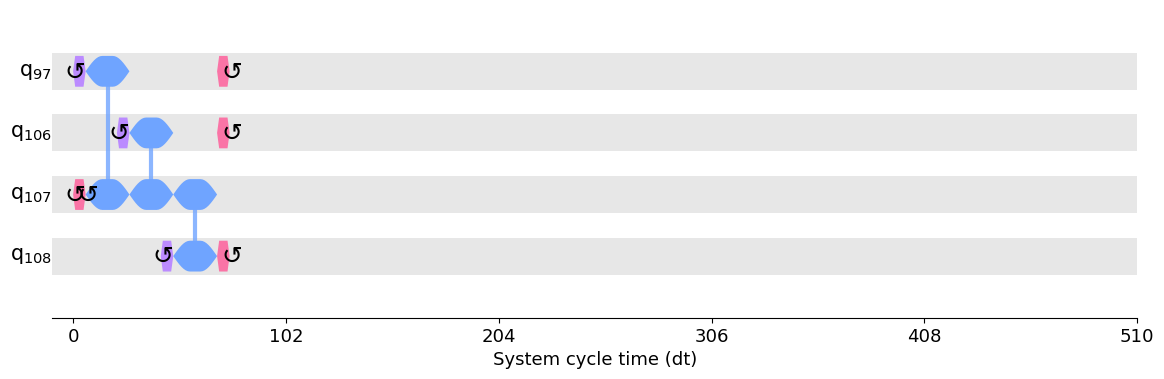

In [26]:
from qiskit.visualization.timeline import draw as draw_timeline, IQXSimple

draw_timeline(ftqc, idle_wires=False, time_range=(0, 500), style=IQXSimple())

In [27]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(optimization_level=3, backend=backend_conventional, scheduling_method="alap")
ctqc = pm.run(qc)
ctqc.draw(idle_wires=False)

┌─────────┐      ┌────┐   ┌───────┐             ┌───────────────┐»
 q_1 -> 97 ───┤ Rz(π/2) ├──────┤ √X ├───┤ Rz(π) ├───────────■─┤ Delay(42[dt]) ├»
           ┌──┴─────────┴──┐┌──┴────┴─┐ └─┬────┬┘ ┌───────┐ │ └───────────────┘»
q_3 -> 106 ┤ Delay(42[dt]) ├┤ Rz(π/2) ├───┤ √X ├──┤ Rz(π) ├─┼──────────────────»
           └──┬─────────┬──┘└──┬────┬─┘┌──┴────┴─┐└───────┘ │                  »
q_0 -> 107 ───┤ Rz(π/2) ├──────┤ √X ├──┤ Rz(π/2) ├──────────■─────────■────────»
           ┌──┴─────────┴──┐┌──┴────┴─┐└──┬────┬─┘┌───────┐           │        »
q_2 -> 108 ┤ Delay(21[dt]) ├┤ Rz(π/2) ├───┤ √X ├──┤ Rz(π) ├───────────■────────»
           └───────────────┘└─────────┘   └────┘  └───────┘                    »
«                 ┌────┐       ┌─────────┐              
« q_1 -> 97 ──────┤ √X ├───────┤ Rz(π/2) ├──────────────
«                 └────┘       └──┬────┬─┘   ┌─────────┐
«q_3 -> 106 ────────■─────────────┤ √X ├─────┤ Rz(π/2) ├
«                   │        ┌────┴────┴────┐└─────────┘
«q_0 -> 107 ────────■────────┤ Delay(6[dt]) ├───────────
«           ┌───────────────┐└────┬────┬────┘┌─────────┐
«q_2 -> 108 ┤ Delay(21[dt]) ├─────┤ √X ├─────┤ Rz(π/2) ├
«           └───────────────┘     └────┘     └─────────┘

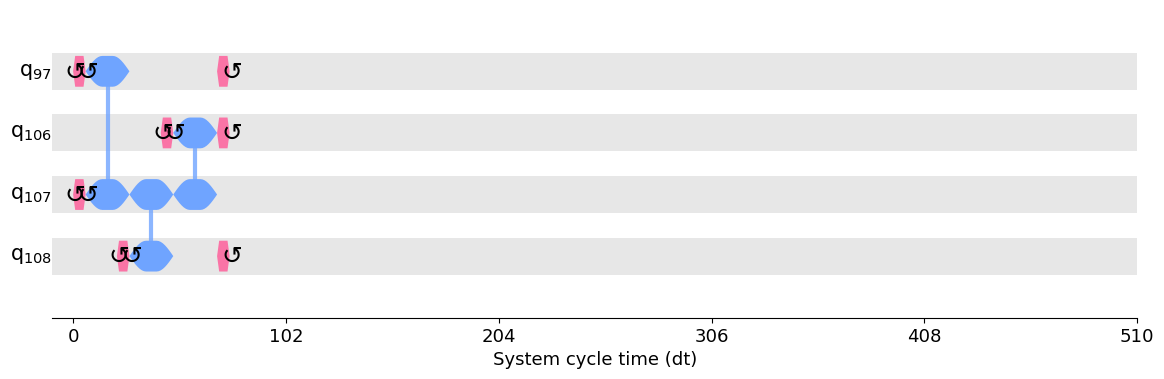

In [28]:
from qiskit.visualization.timeline import draw as draw_timeline, IQXSimple

draw_timeline(ctqc, idle_wires=False, time_range=(0, 500), style=IQXSimple())

In [29]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(optimization_level=3, backend=backend_conventional, scheduling_method="asap")
ctqc = pm.run(qc)
ctqc.draw(idle_wires=False)

┌─────────┐┌────┐ ┌───────┐ ┌───────────────┐         ┌────┐  »
 q_2 -> 97 ┤ Rz(π/2) ├┤ √X ├─┤ Rz(π) ├─┤ Delay(21[dt]) ├──■──────┤ √X ├──»
           ├─────────┤├────┤ ├───────┤ ├───────────────┤  │      └────┘  »
q_3 -> 106 ┤ Rz(π/2) ├┤ √X ├─┤ Rz(π) ├─┤ Delay(42[dt]) ├──┼────────■─────»
           ├─────────┤├────┤┌┴───────┴┐└───────────────┘  │        │     »
q_0 -> 107 ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├────────■──────────■────────■─────»
           ├─────────┤├────┤└┬───────┬┘        │        ┌────┐┌─────────┐»
q_1 -> 108 ┤ Rz(π/2) ├┤ √X ├─┤ Rz(π) ├─────────■────────┤ √X ├┤ Rz(π/2) ├»
           └─────────┘└────┘ └───────┘                  └────┘└─────────┘»
«              ┌─────────┐   ┌───────────────┐
« q_2 -> 97 ───┤ Rz(π/2) ├───┤ Delay(21[dt]) ├
«              └──┬────┬─┘   └──┬─────────┬──┘
«q_3 -> 106 ──────┤ √X ├────────┤ Rz(π/2) ├───
«            ┌────┴────┴────┐   └─────────┘   
«q_0 -> 107 ─┤ Delay(6[dt]) ├─────────────────
«           ┌┴──────────────┤                 
«q_1 -> 108 ┤ Delay(42[dt]) ├─────────────────
«           └───────────────┘

In [61]:
backend_fractional.version

2

In [30]:
ctqc.duration

75